In [ ]:
#za graficke prikaze koriscen kod sa vezbi
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import normal_ad
from sklearn.metrics import r2_score



df_Full_Train_Data = pd.read_csv("data/train.csv")
df_Test_Data = pd.read_csv("data/test.csv")



In [ ]:
def provera_nedostajucih_vrednosti(df):
    missing_values = df.isna().sum()
    non_zero_missing = missing_values[missing_values != 0]
    non_zero_missing_percentage = (non_zero_missing / len(df)) * 100
    return pd.DataFrame({
        'N missing': non_zero_missing,
        '% missing': non_zero_missing_percentage
    })

#print(provera_nedostajucih_vrednosti(df))
#  SleepDuration: 12.7%,
# SocialMediaUsage: 29.3%,
# CampusFacilityRating: 19.3% ,
# PreferredStudyTemperature: 23.4%


Na osnovu analize podataka vidim da cetiri kolone imaju neke nedostajuce vrednosti.
Obicno odbacivanje redova sa nepostojecim podacima bi odbacilo 385 redova odnsno ostalo bi nam samo 61.5% podataka za treniranje

Takodje da mi bio u mogucnosti da koristim spline popunjavanje ili sa polinomom trebao bi mi neki neki prirodni trend u podacima ali podaci u sve cetiri kolone su rasprseni u oblak tacaka.
Dakle ostaje popunjavanje srednjim/medijan vrednostima ili mod vrednostima.
Ostaje i mogucnost da, nakon popunjavanja,treniranja i testiranja, mozemo odbaciti jednu ili vise od kolona gde su bile nedostajuce vrednosti
Za odlucivanje da li da se koristi srdnja vrednost ili nesto drugo cu koristit metrike procene za model nakon treniranja


In [ ]:
def DodajSrednjuNAN(dfOriginal, imeKolone):
    col_mean = dfOriginal[imeKolone].mean()
    dfOriginal[imeKolone] = dfOriginal[imeKolone].fillna(col_mean)


DodajSrednjuNAN(df_Full_Train_Data, 'SleepDuration')
DodajSrednjuNAN(df_Full_Train_Data, 'SocialMediaUsage')
DodajSrednjuNAN(df_Full_Train_Data, 'CampusFacilityRating')
DodajSrednjuNAN(df_Full_Train_Data, 'PreferredStudyTemperature')



In [ ]:
#nakon popunjavanja split na train i validation

df , df_validation = train_test_split(df_Full_Train_Data, train_size=800, test_size=200, random_state=42)

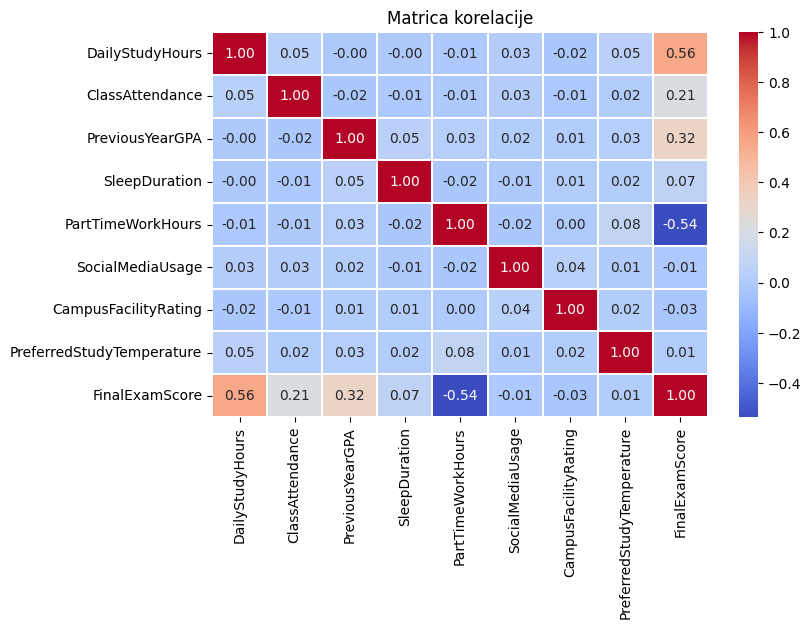

In [ ]:
plt.figure(figsize=(8,5)) # da podesimo velicinu grafika

correlation_matrix = df.corr() # racunamo matricu korelacije

sb.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.1)
plt.title('Matrica korelacije')
plt.show()

Mozemo zakljuciti da izmedju kolona nema znacajne korelacije pa zato ih necu ni odbacivati trenutno.

In [ ]:
#treniranje modela

x_all_col = df.drop(columns=['FinalExamScore'])
x_one_miss = df.drop(columns=['FinalExamScore', 'CampusFacilityRating'])
x_two_miss = df.drop(columns=['FinalExamScore', 'CampusFacilityRating', 'PreferredStudyTemperature'])

x_all_col_Val = df_validation.drop(columns=['FinalExamScore'])
x_one_miss_Val = df_validation.drop(columns=['FinalExamScore', 'CampusFacilityRating'])
x_two_miss_Val = df_validation.drop(columns=['FinalExamScore', 'CampusFacilityRating', 'PreferredStudyTemperature'])

y = df['FinalExamScore']
y_val = df_validation['FinalExamScore']

x_Const_all = sm.add_constant(x_all_col)
x_Const_one_miss = sm.add_constant(x_one_miss)
x_Const_two_miss = sm.add_constant(x_two_miss)

x_Const_all_Val = sm.add_constant(x_all_col_Val)
x_Const_one_miss_Val = sm.add_constant(x_one_miss_Val)
x_Const_two_miss_Val = sm.add_constant(x_two_miss_Val)

modelSveKolone = sm.OLS(y, x_Const_all).fit()
modelJednaNed = sm.OLS(y,x_Const_one_miss).fit()
modelDveNed = sm.OLS(y,x_Const_two_miss).fit()


### Linearnost

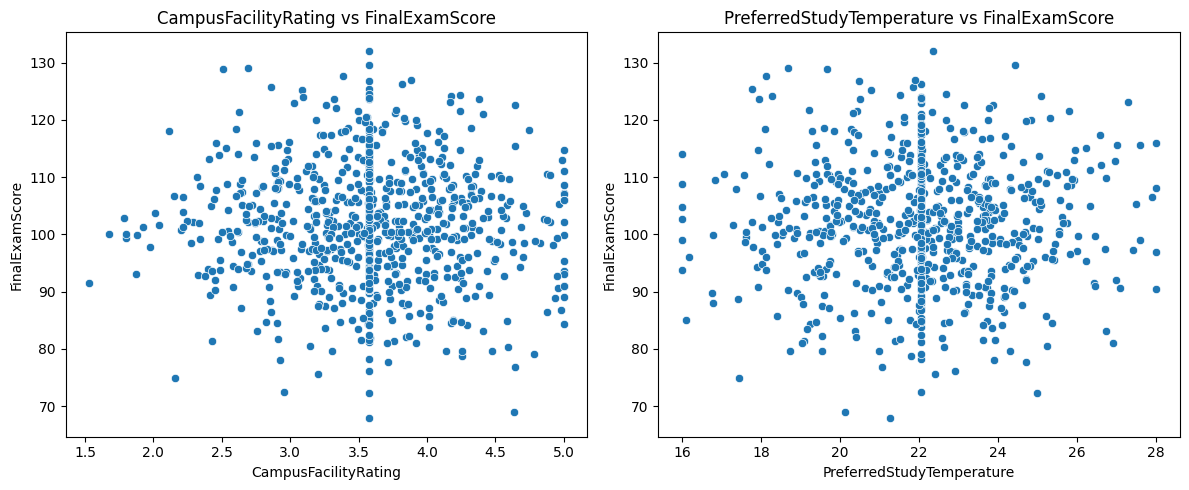

Linearnost: Test P-vrednosti:
Za kolonu DailyStudyHours: 	P-vrednost =0.000 => Hipoteza ne vazi zbog 0.000<=0.05, postoji linarna veza
Za kolonu ClassAttendance: 	P-vrednost =0.000 => Hipoteza ne vazi zbog 0.000<=0.05, postoji linarna veza
Za kolonu PreviousYearGPA: 	P-vrednost =0.000 => Hipoteza ne vazi zbog 0.000<=0.05, postoji linarna veza
Za kolonu SleepDuration: 	P-vrednost =0.023 => Hipoteza ne vazi zbog 0.023<=0.05, postoji linarna veza
Za kolonu PartTimeWorkHours: 	P-vrednost =0.000 => Hipoteza ne vazi zbog 0.000<=0.05, postoji linarna veza
Za kolonu SocialMediaUsage: 	P-vrednost =0.012 => Hipoteza ne vazi zbog 0.012<=0.05, postoji linarna veza
Za kolonu CampusFacilityRating: 	P-vrednost =0.359 => Hipoteza vazi zbog 0.359>=0.05, kolona nema veliki uticaj pri prisudstvu ostalih promenljivih
Za kolonu PreferredStudyTemperature: 	P-vrednost =0.295 => Hipoteza vazi zbog 0.295>=0.05, kolona nema veliki uticaj pri prisudstvu ostalih promenljivih


In [ ]:
#testiranje pretpostavke linearnosti
def p_Test_Linearnost(modelPriv: RegressionResultsWrapper,alpha = 0.05):
    print("Linearnost: Test P-vrednosti:")
    for imeKol, p_vr in modelPriv.pvalues.items():
        if(imeKol == 'const'):
            continue
        if p_vr <= alpha:
            print(f"Za kolonu {imeKol}: \tP-vrednost ={p_vr:.3f} => Hipoteza ne vazi zbog {p_vr:.3f}<={alpha}, postoji linarna veza")
        else:
            print(f"Za kolonu {imeKol}: \tP-vrednost ={p_vr:.3f} => Hipoteza vazi zbog {p_vr:.3f}>={alpha}, kolona nema veliki uticaj pri prisudstvu ostalih promenljivih")



fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Prvi subplot: CampusFacilityRating vs FinalExamScore
sb.scatterplot(x=df['CampusFacilityRating'], y=df['FinalExamScore'], ax=axes[0])
axes[0].set_title('CampusFacilityRating vs FinalExamScore')
axes[0].set_xlabel('CampusFacilityRating')
axes[0].set_ylabel('FinalExamScore')
# Drugi subplot: PreferredStudyTemperature vs FinalExamScore
sb.scatterplot(x=df['PreferredStudyTemperature'], y=df['FinalExamScore'], ax=axes[1])
axes[1].set_title('PreferredStudyTemperature vs FinalExamScore')
axes[1].set_xlabel('PreferredStudyTemperature')
axes[1].set_ylabel('FinalExamScore')
plt.tight_layout()
plt.show()



p_Test_Linearnost(modelSveKolone,0.05)


Na osnovu dva plota iznad zakljucujem da CampusFacilityRating i PreferredStudyTemperature nemaju linarnu vezu sa FinalExamScore. Moze se primjetitit  da CampusFacilityRating i PreferredStudyTemperature nemaju prediktivnu moc pa su prvi kandidati koje bi mogao da izbacim iz modela zbog njegovog pobljsanja.
Takodje ovaj zakljucak vidimo iz T-testa.

In [ ]:
def F_test(modelPriv: RegressionResultsWrapper, alpha = 0.05) -> None:
    print("Linearnost: F-test")
    if modelPriv.f_pvalue <= alpha:
        print('Jedna/vise slobodnih promenljivi ima linarnu zavisnost sa zavisnom promenljivom')
    else:
        print('Verovatno nama linarne zavisnosti izmedju slobodnih promenljivih i zavisne promenljive')

F_test(modelSveKolone, 0.05)

Linearnost: F-test
Jedna/vise slobodnih promenljivi ima linarnu zavisnost sa zavisnom promenljivom


### Nezavisnost gresaka

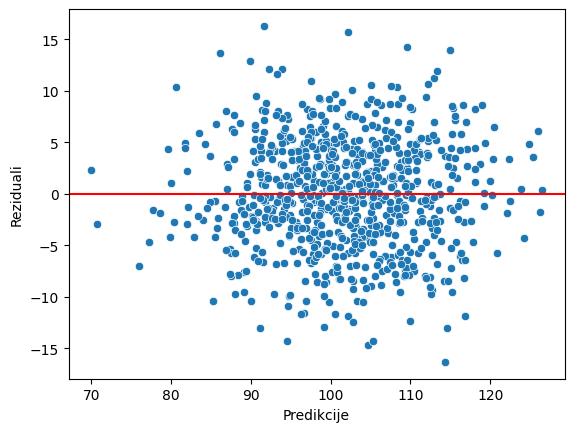

In [ ]:
#nezavisnost gresaka- graficki prikaz
def nezGr_graf(modelPriv: RegressionResultsWrapper):
    sb.scatterplot(x=modelPriv.fittedvalues, y=modelPriv.resid)
    plt.axhline(0, color='red')
    plt.xlabel("Predikcije")
    plt.ylabel("Reziduali")
    plt.show()

nezGr_graf(modelSveKolone)

Na grafu vidimo realtivno dobru distribuciju oko 0 odnsno nema nekog sablona. => Pretpostavka vazi, greske su statisticki nezavisne.

In [ ]:
#Statisticki metod
def Durbin_Watson(modelPriv: RegressionResultsWrapper,):
    print("Nezavisnost gresaka: Test: Durbin-Watson:")
    residuals = modelPriv.resid
    durWat = durbin_watson(resids=residuals)
    if durWat < 1.5:
        print('Pretpostavka ne vazi zato sto je vrednost < 1.5 pa postoji pozitivna autokorelacija gresaka izmedju susednih posmatranja')
    elif durWat > 2:
        print('Pretpostavka ne vazi zato sto je vrednost > 2 pa postoji negativna autokorelacija gresaka izmedju susednih posmatranja')
    else:
        print('Autokorelacija izmedju gresaka ne postoji => pretpostavka vazi')

Durbin_Watson(modelSveKolone)

Nezavisnost gresaka: Test: Durbin-Watson:
Autokorelacija izmedju gresaka ne postoji => pretpostavka vazi


### Normalnost gresaka

Normalnost gresaka: Test srednja vrednost gresaka: 
-0.000000000000023


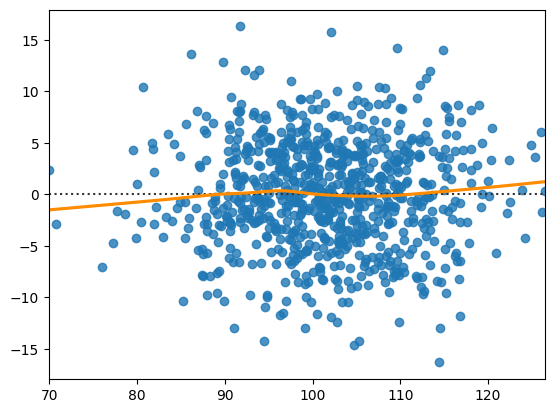

In [ ]:
#Srednja vrednost gresaka mora biti nula tj priblizno nula
def normalnost_Prva_Pret(modelPriv: RegressionResultsWrapper):
    print("Normalnost gresaka: Test srednja vrednost gresaka: ")
    print(f"{modelPriv.resid.mean():.15f}")

    #LOWESS metod

    sb.residplot(x=modelPriv.fittedvalues, y=modelPriv.resid, lowess=True,  line_kws={'color': 'darkorange'})
    plt.show()

normalnost_Prva_Pret(modelSveKolone)

Reziduali se nagomilavaju oko nule pa pretpostavka da se nagomilavaju oko nule vazi.

Normalnost gresaka: Test normalne distribucije
Reziduali su noramlni distribuirani zato sto 0.3147808179969453 >= 0.05 => pretpostavka vazi


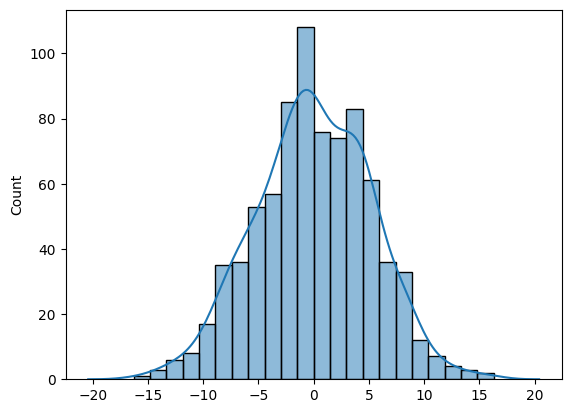

In [ ]:

def Normalna_Distr(modelPriv: RegressionResultsWrapper, alpha = 0.05):
    print("Normalnost gresaka: Test normalne distribucije")
    p_vr = normal_ad(modelPriv.resid)[1]
    if(p_vr >= alpha):
        print(f"Reziduali su noramlni distribuirani zato sto {p_vr} >= {alpha} => pretpostavka vazi")
    else:
        print(f"Reziduali nisu noramlni distribuirani zato sto {p_vr} < {alpha} => pretpostavka ne vazi")

    sb.histplot(modelPriv.resid, kde=True, kde_kws=dict(cut=3))

Normalna_Distr(modelSveKolone,0.05)


Obe pretpostavke vaze => greske su normalno distribuirane

### Pretpostavka jednake varijanse

Jednaka varijansa: Test Goldfeld-Quandt:
Pretpostavka vazi zato sto 0.4687108095601926 >= 0.05 => varijansa je jednaka


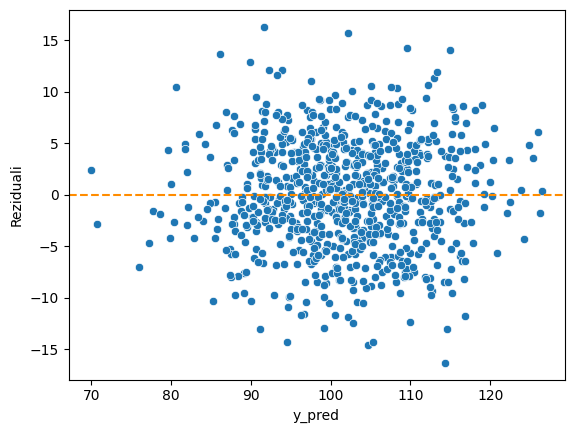

In [ ]:

def QQ_test(modelPriv: RegressionResultsWrapper, alpha = 0.05):
    print("Jednaka varijansa: Test Goldfeld-Quandt:")

    xConst = sm.add_constant(x_all_col)
    p_vr = sm.stats.het_goldfeldquandt(modelPriv.resid, xConst)[1]
    if p_vr >= alpha:
        print(f"Pretpostavka vazi zato sto {p_vr} >= {alpha} => varijansa je jednaka")
    else:
        print(f"Pretpostavka ne vazi zato sto {p_vr} < {alpha} => varijansa nije jednaka")

    sb.scatterplot(x = modelPriv.fittedvalues, y=modelPriv.resid)
    plt.axhline(y=0, color='darkorange', linestyle='--')
    plt.ylabel('Reziduali')
    plt.xlabel('y_pred')
    plt.show()

QQ_test(modelSveKolone, 0.05)




Grafickom metodom vidimo da se reziduali nemaju sablon => pretpostavka jednakih varijansi vazi.

### R2 test modela nad validacionim podacima


In [ ]:
#koricen chatGPT za formulu
def adjusted_r2(y_true, y_pred, n, p):  #n - broj y orginala, p - broj kolona tj x bez konstante
    r2 = r2_score(y_true, y_pred)
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


In [ ]:

y_all_pred = modelSveKolone.predict(x_Const_all_Val)
y_one_miss_pred = modelJednaNed.predict(x_Const_one_miss_Val)
y_two_miss_pred = modelDveNed.predict(x_Const_two_miss_Val)


r_2_score_all = adjusted_r2(y_true=y_val, y_pred=y_all_pred, n = len(y_val), p = 8)
r_2_score_one_miss = adjusted_r2(y_true=y_val, y_pred=y_one_miss_pred, n = len(y_val), p = 7 )
r_2_score_two_miss = adjusted_r2(y_true=y_val, y_pred=y_two_miss_pred, n = len(y_val), p = 6)

#print(f"svi {modelSveKolone.rsquared_adj}, jedna: {modelJednaNed.rsquared_adj}, dve {modelDveNed.rsquared_adj}")
#print(f"Metrika svi: {r_2_score_all:.3f}, jedna nedostaje: {r_2_score_one_miss:.3f}, dve nedostaju: {r_2_score_two_miss:.3f}")
# NA train: svi 0.7443778743386581, jedna: 0.744428409735495, dve 0.7444076803416266
#Na validation: Metrika svi: 0.745, jedna nedostaje: 0.747, dve nedostaju: 0.749
#po trenutnim podacima model bez dve varijable je najbolji

In [ ]:

x_two_miss_Test = df_Test_Data.drop(columns=['FinalExamScore', 'CampusFacilityRating', 'PreferredStudyTemperature'])

y_test = df_Test_Data['FinalExamScore']


x_Const_two_miss_Test = sm.add_constant(x_two_miss_Test)

y_two_miss_pred_test = modelDveNed.predict(x_Const_two_miss_Test)

r_2_score_two_miss_Test = adjusted_r2(y_true=y_test, y_pred=y_two_miss_pred_test, n = len(y_test), p = 6)


print(f"adj_r2 = {r_2_score_two_miss_Test: .3f}")



adj_r2 =  0.746
